# 7000LBSBAI - Programming for Business Analytics
## Week 8 - Task: Why Do Members Cancel?
### 📋 ANSWER VERSION: for checking code and independent study

---

**Module:** Programming for Business Analytics  
**Week:** 8  
**Time:** About 75 minutes, plus optional extensions  
**Topics covered:** Cleaning with a function · Rates for a yes/no outcome · Bands · Dates and membership length · Using Gemini as a tutor

---

### How to use this notebook

| Symbol | Meaning |
|--------|---------|
| ✍️ Worked example | Code is already written -> run it and study the output |
| ➡️ Your turn | Write or complete the code in this cell |
| 💬 What does it mean? | Write a short interpretation of your results |
| 🤖 AI activity | A guided activity using Gemini in Colab |
| 🔴 Extension | For students who finish early (optional) |
| 📝 Hint/Tip | Some friendly help and advice |

To run a cell: click on it and press **Shift + Enter**.

---

## ⚠️ BEFORE YOU CONTINUE

### Save a copy of this notebook

Make sure your notebook is saved to your Google Drive:
- **File → Save a copy in Drive**
- Name it: `Week8_Task_FitLife_Cancellations_YourName.ipynb`

---
## The scenario

**FitLife Gyms** has three gyms: City Centre, Riverside and Northgate. The membership manager has sent you data on **3,000 members** who joined between 2022 and 2024, and asks:

> ### *"Which members are most likely to cancel, and what does that tell us?"*

The data was taken on **31 January 2025**.

| Column | What it holds |
|--------|---------------|
| `member_id` | A unique ID for each member |
| `join_date` | The date they joined |
| `cancel_date` | The date they cancelled (**empty if they have not cancelled**) |
| `home_gym` | City Centre, Riverside or Northgate |
| `membership_type` | Monthly Flex, Annual or Off-Peak |
| `monthly_fee` | Their monthly fee (£) |
| `age` | Age in years |
| `distance_km` | Distance from home to their gym (km) |
| `visits_per_month` | Average gym visits per month |
| `classes_per_month` | Average classes attended per month |
| `pt_sessions_per_month` | Personal training sessions per month |
| `monthly_spend` | Total spent per month: fee, classes, personal training and café (£) |
| `cancelled` | Yes or No |

> 📝 **This task is more open than earlier weeks.** Some cells give you an outline; others just ask a question. The hints say which part of the code-along to look at. You will use FitLife again in Weeks 9 and 10, so keep this notebook.

---
# Section 1: Load and inspect

In [1]:
# ➡️ 1.1 Import pandas, numpy, matplotlib and seaborn, set the seaborn theme, and load the data as raw
url = "https://raw.githubusercontent.com/7000lbsbai/7000LBSBAI/main/datasets/fitlife_members.csv"

# Write your code below this line
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
raw = pd.read_csv(url)
print(f"Data loaded: {raw.shape[0]} rows and {raw.shape[1]} columns")

# ✅ 3025 rows and 13 columns

Data loaded: 3025 rows and 13 columns


In [2]:
# ➡️ 1.2 Show the first 5 rows, then the data types and non-null counts
print(raw.head())
raw.info()

# ✅ monthly_fee is text (it contains £ signs); cancel_date has many missing values;
#    visits_per_month has a few missing values

  member_id   join_date cancel_date     home_gym membership_type monthly_fee  \
0   FL00821  2022-02-13  2022-05-29    Riverside    Monthly Flex      £34.99   
1   FL01008  2023-10-24  2024-08-13  City Centre        Off-Peak      £22.99   
2   FL00558  2023-07-31         NaN    Riverside          ANNUAL      £17.99   
3   FL00539  2023-05-19         NaN  City Centre          Annual      £22.99   
4   FL01725  2024-09-26  2024-12-11    Riverside    Monthly Flex      £34.99   

   age  distance_km  visits_per_month  classes_per_month  \
0   18          4.9              10.0                  4   
1   35          5.0               9.0                  3   
2   18          4.4               6.0                  2   
3   37          5.8              10.0                  1   
4   24          2.4              10.0                  4   

   pt_sessions_per_month  monthly_spend cancelled  
0                      0          73.24       Yes  
1                      0          51.70       Yes  
2 

---
# Section 2: Clean the data with a function

In [3]:
# ➡️ 2.1 Spot the problems: print the missing values, duplicates, membership_type values, the smallest and largest age, and a few monthly_fee values
print(raw.isnull().sum())
print()
print(f"Duplicate rows: {raw.duplicated().sum()}")
print()
print(raw['membership_type'].value_counts())
print()
print(f"Age: {raw['age'].min()} to {raw['age'].max()}")
print(raw['monthly_fee'].head())

# ✅ 25 duplicates; 15 spellings of 3 membership types; fees stored as text with £;
#    55 missing visits; impossible ages (0, 7 and 112); 2,320 empty cancel dates

member_id                   0
join_date                   0
cancel_date              2320
home_gym                    0
membership_type             0
monthly_fee                 0
age                         0
distance_km                 0
visits_per_month           55
classes_per_month           0
pt_sessions_per_month       0
monthly_spend               0
cancelled                   0
dtype: int64

Duplicate rows: 25

membership_type
Monthly Flex     1221
Annual            892
Off-Peak          647
MONTHLY FLEX       31
 Monthly Flex      30
Monthly Flex       30
ANNUAL             29
monthly flex       28
 Annual            25
annual             23
Annual             21
OFF-PEAK           15
 Off-Peak          12
off-peak           12
Off-Peak            9
Name: count, dtype: int64

Age: 0 to 112
0    £34.99
1    £22.99
2    £17.99
3    £22.99
4    £34.99
Name: monthly_fee, dtype: object


### ➡️ 2.2 Write a cleaning function

Complete the function below. Each `#` comment is one step: write the code for it underneath.

> 📝 **Hint:** code-along Block 1, and your Week 3 notebook for the fixes.

> ⚠️ **Not every missing value is an error.** `cancel_date` is empty for members who have **not cancelled**. That is correct, so do **not** fill it or remove those rows.

In [4]:
# ➡️ 2.2 Complete the cleaning function
def clean_members(data):
    """Clean the FitLife member data."""
    data = data.copy()

    # 1. Remove duplicate rows
    data = data.drop_duplicates()

    # 2. Tidy membership_type (remove spaces, consistent capitals)
    data['membership_type'] = data['membership_type'].str.strip().str.title()

    # 3. Convert monthly_fee to a number (remove the £ sign first)
    data['monthly_fee'] = pd.to_numeric(data['monthly_fee'].str.replace('£', ''))

    # 4. Keep only realistic ages (18 to 100)
    data = data[(data['age'] >= 18) & (data['age'] <= 100)]

    # 5. Fill missing visits_per_month with the median
    data['visits_per_month'] = data['visits_per_month'].fillna(data['visits_per_month'].median())

    return data

In [5]:
# ➡️ 2.3 Use your function to create df, then check: print the shape, duplicates, membership types, age range, the data type of monthly_fee, and missing values
df = clean_members(raw)

print(f"Shape: {df.shape}")
print(f"Duplicates: {df.duplicated().sum()}")
print(f"Membership types: {sorted(df['membership_type'].unique())}")
print(f"Age: {df['age'].min()} to {df['age'].max()}")
print(f"monthly_fee is now: {df['monthly_fee'].dtype}")
print(df.isnull().sum())

# ✅ (2997, 13); 0 duplicates; 3 membership types; ages 18 to 75; monthly_fee is float64;
#    the only missing values left are cancel_date (members who have not cancelled)

Shape: (2997, 13)
Duplicates: 0
Membership types: ['Annual', 'Monthly Flex', 'Off-Peak']
Age: 18 to 75
monthly_fee is now: float64
member_id                   0
join_date                   0
cancel_date              2300
home_gym                    0
membership_type             0
monthly_fee                 0
age                         0
distance_km                 0
visits_per_month            0
classes_per_month           0
pt_sessions_per_month       0
monthly_spend               0
cancelled                   0
dtype: int64


### ✏️ 2.4 Your cleaning log

- List each change your function makes, and why.
- Explain your decision about the empty `cancel_date` values.

**MODEL ANSWER:**

- **Removed 25 duplicate rows**, so no member is counted twice.
- **Tidied `membership_type`**: 15 spellings became 3 types.
- **Converted `monthly_fee` to a number** by removing the £ sign, so it can be used in calculations.
- **Removed 3 members with impossible ages** (0, 7 and 112): almost certainly typing errors.
- **Filled 55 missing `visits_per_month` with the median** (8 visits): the median is not affected by extreme values, and dropping those members would lose the rest of their data.
- **Kept the empty `cancel_date` values**: they are **not errors**. They show that the member has not cancelled, so filling or removing them would be wrong.

Final dataset: **2,997 members**.

---
# Section 3: Cancellation rates

In [6]:
# ➡️ 3.1 Create a column cancelled_flag (1 for Yes, 0 for No). Print the overall cancellation rate (%) and the number of members who cancelled
df['cancelled_flag'] = np.where(df['cancelled'] == 'Yes', 1, 0)

print(f"Cancellation rate: {df['cancelled_flag'].mean() * 100:.1f}%")
print(f"Members who cancelled: {df['cancelled_flag'].sum()} of {len(df)}")

# ✅ 23.3%: 697 of 2,997 members

Cancellation rate: 23.3%
Members who cancelled: 697 of 2997


> 📝 **Hint:** code-along Block 2.

membership_type
Monthly Flex    36.5
Off-Peak        19.2
Annual           8.1
Name: cancelled_flag, dtype: float64


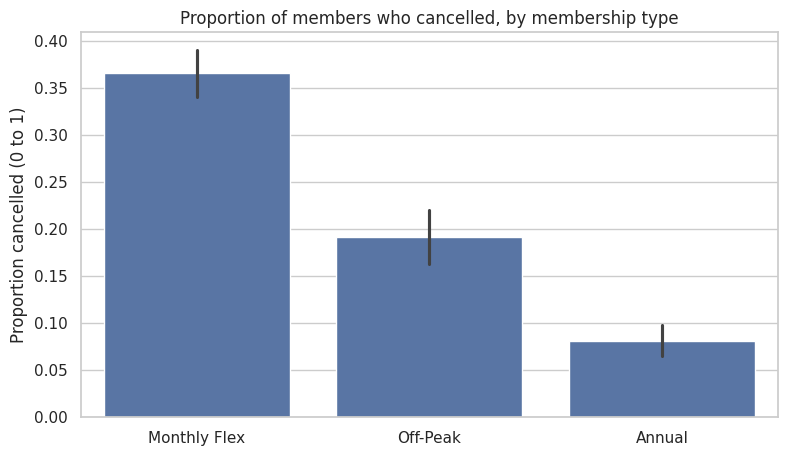

In [7]:
# ➡️ 3.2 The cancellation rate (%) for each membership_type, highest first, and a bar chart of the rates
rate_by_type = (df.groupby('membership_type')['cancelled_flag'].mean() * 100).round(1).sort_values(ascending=False)
print(rate_by_type)

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='membership_type', y='cancelled_flag', order=rate_by_type.index)
plt.title('Proportion of members who cancelled, by membership type')
plt.xlabel('')
plt.ylabel('Proportion cancelled (0 to 1)')
plt.show()

# ✅ Monthly Flex 36.5%, Off-Peak 19.2%, Annual 8.1%

In [8]:
# ➡️ 3.3 A crosstab of home_gym and cancelled, as percentages of each gym, rounded to 1 decimal place
(pd.crosstab(df['home_gym'], df['cancelled'], normalize='index') * 100).round(1)

# ✅ Cancelled: Northgate 28.1%, City Centre 22.0%, Riverside 21.2%

cancelled,No,Yes
home_gym,,
City Centre,78.0,22.0
Northgate,71.9,28.1
Riverside,78.8,21.2


### 💬 What does it mean?

- Which membership type has the highest cancellation rate, and how does it compare with the others?
- Does the gym make much difference?

**✏️ MODEL ANSWER:**

**23.3%** of members have cancelled. Membership type makes a **very large** difference: **36.5%** of Monthly Flex members have cancelled, more than four times the rate for Annual members (**8.1%**), with Off-Peak in between (**19.2%**). This makes sense: Monthly Flex members can leave at any time, while Annual members are committed for a year. The gym matters much less: **Northgate** is a little higher (**28.1%**) than City Centre (22.0%) and Riverside (21.2%), which may be worth investigating, but the difference is much smaller.

---
# Section 4: Bands

In [9]:
# ➡️ 4.1 Create age bands (18-24, 25-34, 35-49, 50+), then print the number of members and the cancellation rate (%) in each band
df['age_band'] = pd.cut(df['age'], bins=[17, 24, 34, 49, 100], labels=['18-24', '25-34', '35-49', '50+'])

print(df['age_band'].value_counts().sort_index())
print((df.groupby('age_band', observed=True)['cancelled_flag'].mean() * 100).round(1))

# ✅ 18-24: 29.2%, 25-34: 22.3%, 35-49: 21.2%, 50+: 26.7%

age_band
18-24     424
25-34     875
35-49    1365
50+       333
Name: count, dtype: int64
age_band
18-24    29.2
25-34    22.3
35-49    21.2
50+      26.7
Name: cancelled_flag, dtype: float64


> 📝 **Hint:** code-along Block 3. The first edge is 17 so that 18-year-olds are included in the first band.

In [10]:
# ➡️ 4.2 Use pd.qcut() to split visits_per_month into four groups, then print the number of members and the cancellation rate (%) in each
df['visits_band'] = pd.qcut(df['visits_per_month'], 4, labels=['Lowest 25%', 'Second', 'Third', 'Highest 25%'])

print(df['visits_band'].value_counts().sort_index())
print((df.groupby('visits_band', observed=True)['cancelled_flag'].mean() * 100).round(1))

# ✅ 40.6%, 24.3%, 16.4%, 5.4%. The groups are not exactly equal, because many members
#    have the same number of visits

visits_band
Lowest 25%     892
Second         701
Third          813
Highest 25%    591
Name: count, dtype: int64
visits_band
Lowest 25%     40.6
Second         24.3
Third          16.4
Highest 25%     5.4
Name: cancelled_flag, dtype: float64


### ➡️ 4.3 Your choice: distance bands

Choose your **own** band edges for `distance_km`, then calculate the cancellation rate in each band and draw a bar chart. Think about edges that would make sense to the manager.

distance_band
0-2 km     18.2
2-5 km     21.3
5-10 km    27.4
10+ km     40.7
Name: cancelled_flag, dtype: float64


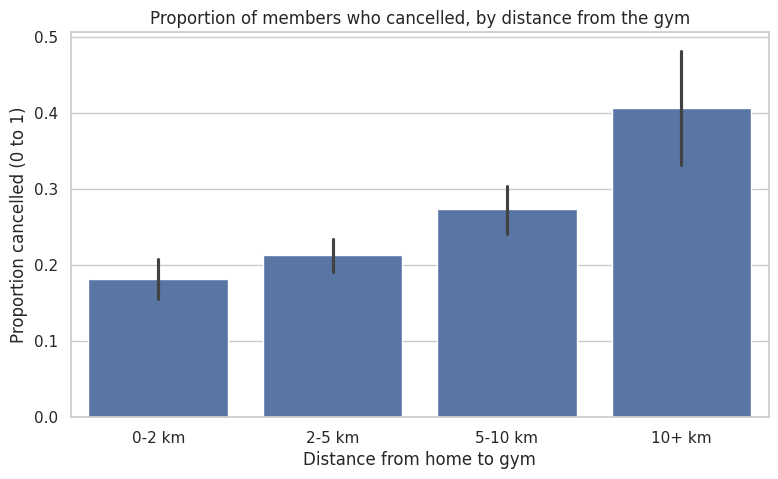

In [11]:
# ➡️ 4.3 Distance bands of your choice, the cancellation rate in each, and a bar chart
df['distance_band'] = pd.cut(df['distance_km'], bins=[0, 2, 5, 10, 30], labels=['0-2 km', '2-5 km', '5-10 km', '10+ km'])

print((df.groupby('distance_band', observed=True)['cancelled_flag'].mean() * 100).round(1))

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='distance_band', y='cancelled_flag')
plt.title('Proportion of members who cancelled, by distance from the gym')
plt.xlabel('Distance from home to gym')
plt.ylabel('Proportion cancelled (0 to 1)')
plt.show()

# ✅ With these edges: 18.2%, 21.3%, 27.4%, 40.7%. Other sensible edges are fine

### 💬 What does it mean?

- How is cancellation linked to how often members visit, and how far away they live?
- Look at the age bands. Which ages cancel most? Is the pattern a straight line?

**✏️ MODEL ANSWER:**

Members who visit least are by far the most likely to cancel: **40.6%** of the lowest quarter for visits have cancelled, against just **5.4%** of the highest quarter. Distance matters too: **18.2%** of members within 2 km have cancelled, rising to **40.7%** of those over 10 km away. Age shows a **U-shape**: the **youngest** (18-24, **29.2%**) and **oldest** (50+, **26.7%**) cancel most, while members aged 25 to 49 cancel least (about 22%). This is **not a straight line**, so a single correlation would hide it: a good reason to look at bands.

---
# Section 5: Dates: how long did members stay?

To work out **how long** each member has belonged, you need an end date:

- For members who **cancelled**, the end date is their `cancel_date`.
- For members who **have not cancelled**, it is the date the data was taken: **31 January 2025**.

`.fillna()` can fill the empty cancel dates with that date. Then subtract the join date to get the number of days, and divide by **30.44** (the average number of days in a month) to get months.

> 📝 **Hint:** code-along Block 4. `pd.Timestamp('2025-01-31')` creates a single date.

In [12]:
# ➡️ 5.1 Convert join_date and cancel_date to dates, then create a column tenure_months (rounded to 1 decimal place)
df['join_date'] = pd.to_datetime(df['join_date'])
df['cancel_date'] = pd.to_datetime(df['cancel_date'])

end_date = df['cancel_date'].fillna(pd.Timestamp('2025-01-31'))
df['tenure_months'] = ((end_date - df['join_date']).dt.days / 30.44).round(1)

print(df['tenure_months'].describe().round(1))

# ✅ From 0.5 to 37.0 months; median 13.8

count    2997.0
mean       15.8
std        10.9
min         0.5
25%         5.8
50%        13.8
75%        25.2
max        37.0
Name: tenure_months, dtype: float64


In [13]:
# ➡️ 5.2 The median tenure_months for members who cancelled and for those who stayed, and the percentage of cancellations that happened within 6 months of joining
print(df.groupby('cancelled')['tenure_months'].median())

cancelled_members = df[df['cancelled'] == 'Yes']
print(f"Cancelled within 6 months: {(cancelled_members['tenure_months'] <= 6).mean() * 100:.1f}%")

# ✅ Median: stayed 19.05 months (about 19), cancelled 4.6 months; 65.9% cancelled within 6 months

cancelled
No     19.05
Yes     4.60
Name: tenure_months, dtype: float64
Cancelled within 6 months: 65.9%


> 📝 **Hint:** for the percentage, filter to the members who cancelled, then take the mean of a True/False condition: True counts as 1, so the mean is a rate.

### 💬 What does it mean?

- When do members tend to cancel?
- What could FitLife do with this information?

**✏️ MODEL ANSWER:**

Members who cancelled left after a median of only **4.6 months**, and **65.9%** of cancellations happened within the **first six months**. Members who stay have been with FitLife for a median of **about 19 months**. So the first few months are when members are most at risk. FitLife could focus its retention efforts on **new members**: for example, a welcome programme, a free personal training session, or a check-in call in the first months, especially for Monthly Flex members and those who visit rarely.

---
# Section 6: 🤖 Using Gemini as a tutor

This week you use **Gemini in Colab** for the first time, as a **tutor**: to **explain** code and errors, **not** to write code for you.

### Turn on Gemini (keep code completions off)

1. Go to **Tools → Settings → AI Assistance**.
2. **Uncheck** `Hide generative AI features`, so that Gemini appears.
3. Keep `Show AI-powered inline completions` **unchecked**, so Colab does not write code as you type.
4. Close the settings. Open the **Gemini** chat panel from the Gemini (✨) button.

> 📝 Colab's menu names sometimes change. If you cannot find a setting, ask your tutor.

### This week's rules

| ✅ Do ask Gemini to… | ❌ Don't ask Gemini to… |
|---|---|
| Explain what a line of code does | Write code for a task |
| Explain an error message in simple terms | Fix your code for you |
| Explain a concept in a different way | Write your interpretations |

**Always check what it tells you.** AI can be confidently wrong. Record each use in the **AI log** below: you will need examples like these for the AI reflection in Assessment 2.

### 🤖 6.1 Explain a line of code

Choose a line from this notebook that you do not fully understand (for example, the `tenure_months` calculation in 5.1). Ask Gemini:

> *"Explain what this line of Python does, step by step, for a beginner. Do not rewrite it or give me new code: [paste your line]"*

Read the explanation. Does it match what you saw when you ran the code?

### 🤖 6.2 Explain an error

Run the cell below. It gives an **error**. Before fixing anything:

1. Click **Explain error** under the error message (or paste the error into the Gemini chat).
2. Ask Gemini to explain **why** it happens, **without** giving you the corrected code.
3. Then fix it **yourself** in the next cell. (Hint: you created a column in Section 3 that solves this.)

In [14]:
# 🤖 6.2 Run this cell: it gives an error
print(f"Cancellation rate: {df['cancelled'].mean() * 100:.1f}%")

TypeError: Could not convert string 'YesYesNoNoYesYesNoNoNoNoYesNoNoYesNoNoNoYesNoNoNoNoNoNoYesNoNoNoNoNoNoYesNoNoYesNoYesYesNoYesNoNoYesYesNoYesNoNoYesYesYesYesNoNoYesNoNoNoNoNoNoNoNoYesNoNoYesNoNoNoNoNoNoNoNoNoYesNoNoNoNoNoYesNoNoYesYesNoYesNoNoNoNoNoNoNoNoNoNoYesNoNoNoYesNoYesNoNoNoNoNoNoNoYesNoNoYesYesNoNoNoNoNoYesNoNoNoNoNoNoNoYesNoNoNoYesYesYesNoNoNoNoNoNoNoNoYesYesNoNoNoNoYesNoNoYesNoNoNoNoYesYesNoNoYesNoNoNoNoYesYesNoYesNoNoNoYesNoNoNoNoNoYesNoYesYesNoNoNoYesNoYesYesYesNoNoNoYesNoNoNoYesNoNoYesNoNoYesNoNoNoNoNoYesNoNoYesNoNoNoYesNoNoYesYesNoYesNoNoNoNoYesNoNoNoNoNoYesNoNoNoNoNoYesNoNoNoYesNoNoNoNoNoNoNoNoNoYesNoYesNoNoNoNoNoNoNoYesNoNoYesNoYesYesNoNoNoNoNoNoNoNoNoNoNoNoYesNoNoNoYesNoNoNoNoNoNoYesYesNoYesYesYesNoNoNoNoNoYesNoNoYesYesNoYesYesNoNoYesNoNoYesNoNoYesNoYesNoNoNoYesNoYesNoNoYesNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoYesNoNoNoNoYesNoNoNoYesYesNoNoNoNoNoYesNoNoNoNoNoYesNoNoNoNoNoNoNoYesNoYesNoNoNoNoNoYesNoNoYesNoNoNoYesNoNoNoYesNoNoYesNoNoNoNoNoNoNoNoNoNoNoNoNoNo

In [15]:
# 🤖 6.2 Your fixed version
print(f"Cancellation rate: {df['cancelled_flag'].mean() * 100:.1f}%")

# cancelled holds the text 'Yes' and 'No', and you cannot take the mean of text.
# cancelled_flag holds 1s and 0s, so its mean is the rate: 23.3%

Cancellation rate: 23.3%


### 📓 6.3 Your AI log

Fill in one row for each time you used Gemini. Keep adding to this log in Weeks 9 to 11.

| Date | What I asked | What Gemini said (in my own words) | Was it right? How did I check? | Did I use it? |
|---|---|---|---|---|
| *Example* | Explain the `tenure_months` line, step by step | It fills empty cancel dates with 31 Jan 2025, subtracts the join date to get days, then divides by 30.44 to get months | Yes: I printed a few rows and checked one member's dates by hand | Yes: it helped me write my interpretation of membership length |
| *Example* | Explain the error from `df['cancelled'].mean()` | You cannot calculate a mean of text; the column contains 'Yes' and 'No' | Yes: `df['cancelled'].dtype` showed it was text | Yes: I used `cancelled_flag` instead |

*A good log is specific: the exact question, a short summary in your own words, and how you checked it.*

---
# Section 7: Summarise your findings

### ✏️ 7.1 Key findings

- Write **three key findings** that answer the manager's question, with numbers.

**MODEL ANSWER:**

1. **Membership type is the strongest factor**: 36.5% of Monthly Flex members have cancelled, against 8.1% of Annual members.
2. **Members who visit less, or live further away, cancel more**: 40.6% of the lowest quarter for visits have cancelled, against 5.4% of the highest; and 40.7% of members over 10 km away, against 18.2% within 2 km.
3. **Most cancellations happen early**: 65.9% happen within six months of joining (median 4.6 months).

### ✏️ 7.2 Limitations, and what to look at next

- What are the **limitations** of this analysis?
- Each finding looks at **one** factor at a time. Why might that be a problem?

**MODEL ANSWER:**

- Each finding looks at **one factor at a time**. The factors may be linked: for example, Monthly Flex members might also visit less, so it is hard to tell which really matters. **Next week** you will look at factors **together**, and in Week 10 you will use a regression model to separate them.
- Low visits might be a **sign** that someone is about to cancel rather than a **cause** (correlation is not causation).
- Some bands are **small** (only 172 members live over 10 km away), so their rates are less reliable.
- We do not know **why** members cancelled (for example, moving away or cost), as the data has no reasons.

---
## 🔴 Extension 1: a function for rate tables

Write a function `rate_table(data, column)` that returns the **number of members** and the **cancellation rate (%)** for each group in a column, highest rate first. Then use it for `membership_type`, `home_gym` and `age_band`.

> 📝 `.agg(['count', 'mean'])` gives both at once.

In [16]:
# 🔴 Extension 1: a rate table function
def rate_table(data, column):
    """Number of members and cancellation rate (%) for each group in a column."""
    table = data.groupby(column, observed=True)['cancelled_flag'].agg(['count', 'mean'])
    table['rate_%'] = (table['mean'] * 100).round(1)
    return table[['count', 'rate_%']].sort_values('rate_%', ascending=False)

for col in ['membership_type', 'home_gym', 'age_band']:
    print(rate_table(df, col))
    print()

# Next week you will use loops like this to automate your EDA

                 count  rate_%
membership_type               
Monthly Flex      1330    36.5
Off-Peak           689    19.2
Annual             978     8.1

             count  rate_%
home_gym                  
Northgate      750    28.1
City Centre   1226    22.0
Riverside     1021    21.2

          count  rate_%
age_band               
18-24       424    29.2
50+         333    26.7
25-34       875    22.3
35-49      1365    21.2



---
## 🔴 Extension 2: do promotions bring loyal members?

Some members pay **less** than the full fee (£34.99 Monthly Flex, £27.99 Annual, £22.99 Off-Peak) because they joined on a promotion. Create a column showing whether each member pays the **full price** or a **discount**, then compare the cancellation rates.

In [17]:
# 🔴 Extension 2: promotions and cancellation
full_prices = [34.99, 27.99, 22.99]
df['price_type'] = np.where(df['monthly_fee'].isin(full_prices), 'Full price', 'Discount')

print(df['price_type'].value_counts())
print((df.groupby('price_type')['cancelled_flag'].mean() * 100).round(1))

# ✅ Discount 29.7% against full price 20.2%: members who joined on a promotion are
#    more likely to cancel. Promotions may attract members who are less committed

price_type
Full price    2035
Discount       962
Name: count, dtype: int64
price_type
Discount      29.7
Full price    20.2
Name: cancelled_flag, dtype: float64


---
## ✅ End of Task: Recap

You have used advanced EDA techniques on a new dataset:

- **A cleaning function** that can be reused on new data
- **Rates** for a yes/no outcome, by group and in crosstabs
- **Bands** with `pd.cut()` and `pd.qcut()`, including one you designed
- **Dates**: converting them, and working out how long members stayed
- **Gemini as a tutor**, with an AI log of what you asked and how you checked it

---

### 💾 Before you leave

Make sure your notebook is saved to your Google Drive, if you have not done so already:
- **File → Save a copy in Drive**
- Name it: `Week8_Task_FitLife_Cancellations_YourName.ipynb`

---

### 🔮 Next week

You will look at **several factors together**, automate parts of your EDA with **loops**, and fit your first **regression model**, using this FitLife data. Keep this notebook and your AI log.